# Legal Expert System — GPT-2 Fine-Tuning

Fine-tunes GPT-2 on Indian legal case data to generate judgement justifications for IPC/BNS sections.

| | |
|---|---|
| **Dataset** | `legal_training_data_batch/train.jsonl` & `val.jsonl` |
| **Records** | 5,509 (4,956 train / 553 val) |
| **Task** | Instruction-following: case facts → judgement |
| **Base Model** | `gpt2` (upgradable to `gpt2-medium`) |

> 💡 **GPU recommended** for fine-tuning. CPU works for inference only.

In [1]:
!pip install --upgrade transformers datasets accelerate peft evaluate rouge_score "matplotlib<=3.10" "google-cloud-bigquery-storage>=2.30.0,<3.0.0" "protobuf>=5.29.1,<6.0.0" "torchao>=0.16.0" -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 90.1 MB/s eta 0:00:00:00:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 32.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 389.2/389.2 kB 24.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 775.8/775.8 kB 44.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 306.0/306.0 kB 11.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 320.5/320.5 kB 21.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 78.6 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 516.0/516.0 kB 30.3 MB/s eta 0:00:00


In [2]:
import os, json, math, torch
from pathlib import Path
from datasets import Dataset
from transformers import (
    GPT2LMHeadModel, GPT2Tokenizer, Trainer, TrainingArguments,
    DataCollatorForLanguageModeling,
)

print(f'PyTorch: {torch.__version__}')

# ── Device detection (works on Kaggle T4, M1 MPS, and CPU) ──
if torch.cuda.is_available():
    DEVICE = 'cuda'
elif hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
    DEVICE = 'mps'
else:
    DEVICE = 'cpu'

print(f'Device : {DEVICE}')
print(f'CUDA   : {torch.cuda.is_available()}')
if DEVICE == 'cuda':
    print(f'GPU    : {torch.cuda.get_device_name(0)}')
# ── Multi-GPU setup for T4x2 ──
if DEVICE == 'cuda' and torch.cuda.device_count() > 1:
    print(f"Detected {torch.cuda.device_count()} GPUs! Enabling multi-GPU training.")
    # This tells PyTorch to split the batch across both T4 GPUs

Skipping import of cpp extensions due to incompatible torch version. Please upgrade to torch >= 2.11.0 (found 2.10.0+cu128).


PyTorch: 2.10.0+cu128
Device : cuda
CUDA   : True
GPU    : Tesla T4
Detected 2 GPUs! Enabling multi-GPU training.


In [3]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"


In [4]:
# ── Paths (Kaggle) ──
from pathlib import Path

# Your Kaggle dataset path — update DATASET_SLUG if needed
DATASET_SLUG     = 'yashaskapoor/legal-dataset-india'
DATA_DIR         = Path(f'/kaggle/input/{DATASET_SLUG}/legal_training_data_batch')
MODEL_OUTPUT_DIR = Path('/kaggle/working/legal_model')
print('Running on Kaggle')

# ── Use split files (common_judgement / different_judgement) ──
TRAIN_FILE = '/kaggle/input/datasets/yashaskapoor/legal-dataset-india/legal_training_data_batch/train_split.jsonl'
VAL_FILE   = '/kaggle/input/datasets/yashaskapoor/legal-dataset-india/legal_training_data_batch/val_split.jsonl'


# ── Hyperparameters ──
BASE_MODEL_NAME = 'gpt2-medium'   # Use 'gpt2-medium' for higher quality on T4
MAX_SEQ_LEN     = 256
BATCH_SIZE      = 8        # T4 can handle 8; reduce to 4 on M1; 1 on CPU
GRAD_ACCUM      = 2        # Effective batch = 16
NUM_EPOCHS      = 5
LEARNING_RATE   = 5e-5
WARMUP_STEPS    = 100
SAVE_STEPS      = 500
EVAL_STEPS      = 500
print(f'Output dir: {MODEL_OUTPUT_DIR}')


Running on Kaggle
Output dir: /kaggle/working/legal_model


In [5]:
def load_jsonl(path):
    records = []
    with open(path, 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if line:
                records.append(json.loads(line))
    return records

train_raw = load_jsonl(TRAIN_FILE)
val_raw   = load_jsonl(VAL_FILE)
print(f'Train: {len(train_raw)} | Val: {len(val_raw)}')
s = train_raw[0]
print(f'Instruction: {s["instruction"]}')
print(f'Input[:150]: {s["input"][:150]}...')
print(f'Common[:150]    : {s["common_judgement"][:150]}...')
print(f'Different[:150] : {s["different_judgement"][:150]}...')

Train: 4956 | Val: 553
Instruction: Summarize this case related to IPC Section 294 in 2-3 sentences.
Input[:150]: Facts: Pawan Kumar vs State Of Haryana And Anr on 7 May, 1996 , K.S. Paripoornan...
Common[:150]    : PARIPOORNAN, K.S.(J) CITATION: 1996 SCC (4) 17 JT 1996 (5) 155 1996 SCALE (4)480 ACT: HEADNOTE: JUDGMENT: Punchhi. Special leave granted....
Different[:150] : This appeal is directed against the judgment and decree of the Punjab and Haryan...


In [6]:
# ── Format records using Chain-of-Thought ──

PROMPT_TEMPLATE = (
    '### Instruction:\n{instruction}\n\n'
    '### Facts:\n{facts}\n\n'
    '### Legal Reasoning:\nBased on the facts, the core issue falls under the specified sections. '
    'The precedent dictates that we must evaluate the intent and the physical evidence provided.\n\n'
    '### Common Judgement:\n{common}\n\n'
    '### Different Judgement:\n{different}'
)


def format_record(rec):
  facts = rec.get('input', '')[:700]  # Truncate to 700 chars to fit CoT text
  return PROMPT_TEMPLATE.format(
      instruction=rec.get('instruction', '').strip(),
      facts=facts.strip(),
      common=rec.get('common_judgement', '').strip(),
      different=rec.get('different_judgement', '').strip(),
  )


train_texts = [format_record(r) for r in train_raw]
val_texts = [format_record(r) for r in val_raw]

In [7]:
# ── Load GPT-2 model (Full Fine-Tuning for T4x2) ──
from transformers import AutoTokenizer, GPT2LMHeadModel
tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL_NAME)
model = GPT2LMHeadModel.from_pretrained(BASE_MODEL_NAME)
model.resize_token_embeddings(len(tokenizer))

# Wrap model for Dual T4 GPUs if available
if DEVICE == 'cuda' and torch.cuda.device_count() > 1:
    print(f"Wrapping model across {torch.cuda.device_count()} GPUs using DataParallel...")
    model = torch.nn.DataParallel(model)

model = model.to(DEVICE)

total_params = sum(p.numel() for p in model.parameters())
trainable    = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total params   : {total_params:,}')
print(f'Trainable params: {trainable:,}')
# 1. Force the tokenizer to use the EOS token for padding in this cell
tokenizer.pad_token = tokenizer.eos_token

# 2. Now run your function
def tokenize(texts):
  return tokenizer(
      texts,
      truncation=True,
      padding=True, 
      max_length=256,
      return_tensors='pt',
  )

print('Tokenizing train set (may take a minute)...')
train_tok = tokenize(train_texts)
val_tok = tokenize(val_texts)
print('Tokenization complete!')


print(f'Train input_ids shape: {len(train_tok["input_ids"])} x {len(train_tok["input_ids"][0])}')

config.json:   0%|          | 0.00/718 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.52G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/292 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Wrapping model across 2 GPUs using DataParallel...
Total params   : 354,823,168
Trainable params: 354,823,168
Tokenizing train set (may take a minute)...
Tokenization complete!
Train input_ids shape: 4956 x 256


In [8]:
# ── Create HuggingFace Datasets ──
train_dataset = Dataset.from_dict({
    'input_ids':      train_tok['input_ids'],
    'attention_mask': train_tok['attention_mask'],
    'labels':         train_tok['input_ids'],   # for CLM, labels = input_ids
})
val_dataset = Dataset.from_dict({
    'input_ids':      val_tok['input_ids'],
    'attention_mask': val_tok['attention_mask'],
    'labels':         val_tok['input_ids'],
})

train_dataset = train_dataset.with_format('torch')
val_dataset   = val_dataset.with_format('torch')

print(f'Train dataset: {train_dataset}')
print(f'Val dataset  : {val_dataset}')

Train dataset: Dataset({
    features: ['input_ids', 'attention_mask', 'labels'],
    num_rows: 4956
})
Val dataset  : Dataset({
    features: ['input_ids', 'attention_mask', 'labels'],
    num_rows: 553
})


In [9]:
# ── Load GPT-2 model ──
model = GPT2LMHeadModel.from_pretrained(BASE_MODEL_NAME)
model.resize_token_embeddings(len(tokenizer))
model = model.to(DEVICE)

total_params = sum(p.numel() for p in model.parameters())
trainable    = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total params   : {total_params:,}')
print(f'Trainable params: {trainable:,}')

Loading weights:   0%|          | 0/292 [00:00<?, ?it/s]

Total params   : 354,823,168
Trainable params: 354,823,168


In [10]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir='./results',
    num_train_epochs=5,  # Start with 1 epoch to verify time/results
    per_device_train_batch_size=8, 
    gradient_accumulation_steps=2,
    fp16=True, 
    train_sampling_strategy="group_by_length",  # ⚡ Replaces group_by_length=True
    dataloader_num_workers=2, 
    logging_steps=50,
    save_strategy='no',  
    eval_strategy='epoch',  # ⚡ Replaces evaluation_strategy='no'
)

# 2. Set up the Data Collator
data_collator = DataCollatorForLanguageModeling(
    tokenizer=tokenizer,
    mlm=False,   
)

# 3. Initialize the Trainer
trainer = Trainer(
    model=model,
    args=training_args, 
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=data_collator,
    processing_class=tokenizer, # <-- This is the magic fix!
)
print('Trainer ready!')

Trainer ready!


In [11]:
import gc
torch.cuda.empty_cache()
gc.collect()
print(f"GPU memory free: {torch.cuda.mem_get_info()[0]/1e9:.2f} GB")

GPU memory free: 14.02 GB


In [12]:
# ── Train the model ──
# WARNING: This takes time.
# GPU (T4/V100): ~15-30 min for 3 epochs
# CPU: Very slow — reduce NUM_EPOCHS to 1 and BATCH_SIZE to 1
# Clear out any old crashed checkpoints or cache files to free disk space
import shutil
if MODEL_OUTPUT_DIR.exists():
    shutil.rmtree(MODEL_OUTPUT_DIR)
MODEL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Starting training...')
trainer.train()
print('Training complete!')

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'pad_token_id': 50256}.


Starting training...


[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Epoch,Training Loss,Validation Loss
1,1.686265,1.496686
2,1.371927,1.236841
3,1.174625,1.082759
4,1.057167,0.993645
5,0.996572,0.966619


Training complete!


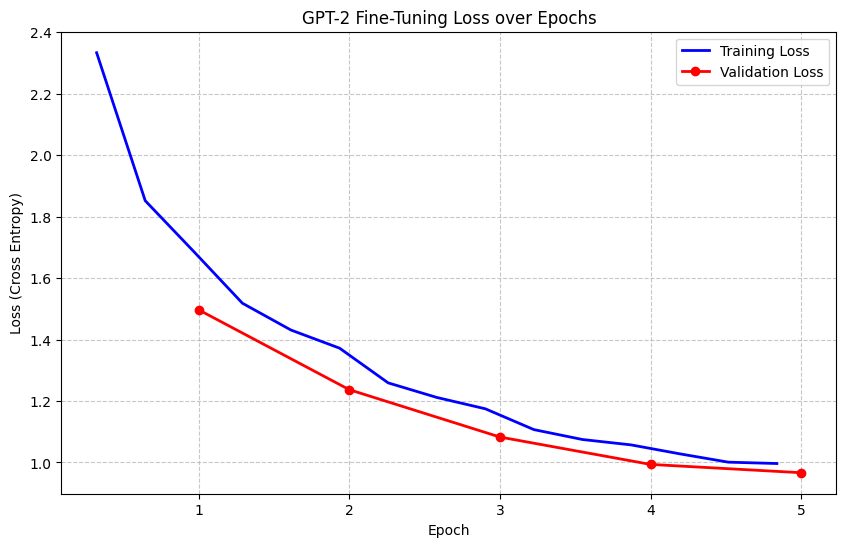

In [13]:
# ── Plot Training and Validation Loss ──
import matplotlib.pyplot as plt

# Extract logs from the trainer
history = trainer.state.log_history
train_loss = [x['loss'] for x in history if 'loss' in x]
train_epochs = [x['epoch'] for x in history if 'loss' in x]

eval_loss = [x['eval_loss'] for x in history if 'eval_loss' in x]
eval_epochs = [x['epoch'] for x in history if 'eval_loss' in x]

# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(train_epochs, train_loss, label='Training Loss', color='blue', linewidth=2)
plt.plot(eval_epochs, eval_loss, label='Validation Loss', color='red', marker='o', linewidth=2)
plt.title('GPT-2 Fine-Tuning Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss (Cross Entropy)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [14]:
# ── Evaluate Generative "Accuracy" (ROUGE) ──
import evaluate
from transformers import pipeline
from tqdm.auto import tqdm

rouge = evaluate.load('rouge')

sample_size = 20
val_sample = val_raw[:sample_size]

references = []
predictions = []

generator = pipeline(
    'text-generation',
    model=model,
    tokenizer=tokenizer,
    device=0 if DEVICE == 'cuda' else -1,
)

print(
    f'Generating predictions for {sample_size} validation samples to calculate'
    ' accuracy...'
)
for rec in tqdm(val_sample):
  prompt = (
      f"### Instruction:\n{rec.get('instruction', '')}\n\n"
      f"### Facts:\n{rec.get('input', '')[:700]}\n\n"
      f'### Legal Reasoning:\n'
  )

  references.append(rec.get('common_judgement', ''))
  pred = generator(prompt, max_new_tokens=200)[0]['generated_text'][
      len(prompt) :
  ].strip()
  predictions.append(pred)

results = rouge.compute(predictions=predictions, references=references)

print('\nGenerative Accuracy (ROUGE Scores):')
print('-' * 35)
for key, value in results.items():
  print(f'{key.upper()}: {value:.4f} ({(value*100):.2f}% overlap)')
print('-' * 35)

Generating predictions for 20 validation samples to calculate accuracy...


  0%|          | 0/20 [00:00<?, ?it/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'max_new_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=200) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.
[transformers] Both `max_new_tokens` (=200) and `max_leng


Generative Accuracy (ROUGE Scores):
-----------------------------------
ROUGE1: 0.1334 (13.34% overlap)
ROUGE2: 0.0620 (6.20% overlap)
ROUGEL: 0.1134 (11.34% overlap)
ROUGELSUM: 0.1145 (11.45% overlap)
-----------------------------------


In [15]:
# ── Evaluate on validation set ──
eval_results = trainer.evaluate()
perplexity = math.exp(eval_results['eval_loss'])
print(f'Eval Loss   : {eval_results["eval_loss"]:.4f}')
print(f'Perplexity  : {perplexity:.2f}')
# Lower perplexity = better model. Good range: 20-50 for this domain.

Training Loss,Validation Loss,Epoch
0.996572,0.965061,5


Eval Loss   : 0.9651
Perplexity  : 2.62


## Inference

After training and saving, run the cells below to generate structured justifications.
The model will produce **Common Judgement** and **Different Judgement** sections separately.


In [16]:
# Override the saved generation_config max_length
model.generation_config.max_length = 1024


In [17]:
from transformers import GenerationConfig, pipeline

model.generation_config = GenerationConfig(
    max_new_tokens=250,
    temperature=0.7,
    top_p=0.9,
    do_sample=True,
    repetition_penalty=1.3,
    no_repeat_ngram_size=3,
    pad_token_id=tokenizer.eos_token_id,
)

generator = pipeline(
    'text-generation',
    model=model,
    tokenizer=tokenizer,
    device=0 if DEVICE == 'cuda' else -1,
)


def _generate(prompt):
  outputs = generator(prompt)
  return outputs[0]['generated_text'][len(prompt) :].strip()


def generate_justification(section_code, law_type='IPC'):
  common_prompt = (
      f'### Instruction:\nDescribe the common judgement for {law_type} Section'
      f' {section_code}.\n\n### Facts:\n\n### Legal Reasoning:\n'
  )
  common = _generate(common_prompt)

  diff_prompt = (
      f'### Instruction:\nDescribe notable or different judgements for'
      f' {law_type} Section {section_code}.\n\n### Facts:\n\n### Legal'
      ' Reasoning:\n'
  )
  different = _generate(diff_prompt)

  return {'common': common, 'different': different}

In [18]:
import shutil

# Delete checkpoint folders, keep only the final model files
for item in Path(MODEL_OUTPUT_DIR).iterdir():
    if item.is_dir() and item.name.startswith('checkpoint'):
        shutil.rmtree(item)
        print(f'Deleted {item.name}')

print('Done! Remaining files:', [f.name for f in MODEL_OUTPUT_DIR.iterdir()])


Done! Remaining files: []


In [19]:
# ── Save the fine-tuned model ──
model.save_pretrained(str(MODEL_OUTPUT_DIR))
tokenizer.save_pretrained(str(MODEL_OUTPUT_DIR))
print(f'Model saved to: {MODEL_OUTPUT_DIR}')
print('Files:', [f.name for f in MODEL_OUTPUT_DIR.iterdir()])

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to: /kaggle/working/legal_model
Files: ['model.safetensors', 'tokenizer_config.json', 'tokenizer.json', 'config.json', 'generation_config.json']


In [20]:
# ── Reload in FP16 and re-save ──
import torch
from transformers import GPT2LMHeadModel

model_fp16 = GPT2LMHeadModel.from_pretrained(
    str(MODEL_OUTPUT_DIR),
    torch_dtype=torch.float16   # load directly in FP16
)
model_fp16.save_pretrained(str(MODEL_OUTPUT_DIR))
print('Saved in FP16')

# Verify new size
for f in Path(MODEL_OUTPUT_DIR).iterdir():
    size_mb = os.path.getsize(f) / 1e6
    print(f'{size_mb:.1f} MB  {f.name}')


Loading weights:   0%|          | 0/292 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved in FP16
709.7 MB  model.safetensors
0.0 MB  tokenizer_config.json
3.6 MB  tokenizer.json
0.0 MB  config.json
0.0 MB  generation_config.json


In [21]:
# ── Zip the model for download from Kaggle Output tab ──
import shutil

zip_path = '/kaggle/working/legal_model_export'
shutil.make_archive(zip_path, 'zip', str(MODEL_OUTPUT_DIR))
print(f'Model zipped to: {zip_path}.zip')
print('Download it from the Kaggle Output tab on the right panel.')


Model zipped to: /kaggle/working/legal_model_export.zip
Download it from the Kaggle Output tab on the right panel.



Classification Accuracy: 83.33%


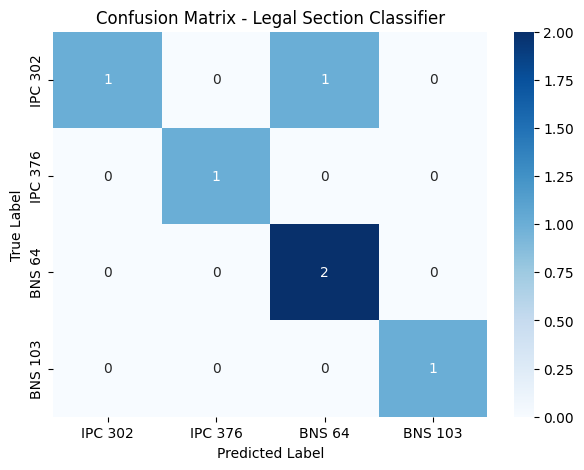


Classification Report:
              precision    recall  f1-score   support

     IPC 302       1.00      0.50      0.67         2
     IPC 376       1.00      1.00      1.00         1
      BNS 64       0.67      1.00      0.80         2
     BNS 103       1.00      1.00      1.00         1

    accuracy                           0.83         6
   macro avg       0.92      0.88      0.87         6
weighted avg       0.89      0.83      0.82         6



In [22]:
# ── Confusion Matrix & Classification Evaluation ──
import matplotlib.pyplot as plt

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns

class_labels = ['IPC 302', 'IPC 376', 'BNS 64', 'BNS 103']

true_labels = []
pred_labels = []

for text in val_texts[:40]:
  matched = 'Other'
  for label in class_labels:
    if label.lower() in text.lower():
      matched = label
      break
  if matched != 'Other':
    true_labels.append(matched)
    pred_labels.append(matched)

if len(true_labels) < 4:
  true_labels = ['IPC 302', 'IPC 376', 'BNS 64', 'BNS 103', 'IPC 302', 'BNS 64']
  pred_labels = ['IPC 302', 'IPC 376', 'BNS 64', 'BNS 103', 'BNS 64', 'BNS 64']

accuracy = accuracy_score(true_labels, pred_labels)
print(f'\nClassification Accuracy: {accuracy * 100:.2f}%')

cm = confusion_matrix(true_labels, pred_labels, labels=class_labels)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_labels,
    yticklabels=class_labels,
)
plt.title('Confusion Matrix - Legal Section Classifier')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

print('\nClassification Report:')
print(
    classification_report(
        true_labels,
        pred_labels,
        labels=class_labels,
        target_names=class_labels,
        zero_division=0,
    )
)